In [1]:
import sys
from pathlib import Path
sys.path[:0] = [str(Path.cwd().parent)]

import numpy as np
import matplotlib.pyplot as plt

from scripts.Hamiltonian import Hamiltonian
from scripts.Lattice import Lattice
from scripts.self_consistency import bdg_sc


In [2]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1
T = 0.001

muD = 1.2 * t
muP = 1.8 * t
muF = 1.4 * t

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = +h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 0 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2


V_prime0 = 1 * t
V_prime = V_prime0 * np.ones(lattice.X)
V_prime[:widthF+widthD] = 0
V_prime[widthF+widthD+widthP:] = 0
V_prime[widthF+widthD] = V_prime0/2
V_prime[widthF+widthD+widthP-1] = V_prime0/2

# bulk p-wave F=0.018

In [ ]:
from scripts.utils import is_hermitian

H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                Fdd_init=[-0.01, 0.01, -0.01j, 0.01j],
                hx=h)

print(is_hermitian(H.build_H_k(np.pi/4)))
print(is_hermitian(H.build_H_k0()))
print(is_hermitian(H.build_H_kindep()))

True
True
True


In [4]:
from scripts.partial_sc import partial_sc

partial_sc(H, temperature=T,
            atol=1e-3, rtol=1e-1, maxiter=500,
            verbose=True)
F, Fuu, Fdd = H.get_correlations()

F0:
Absolute error: 5.187258990181911e-07
Relative error: 518725.89901819115
Average old: 0j
Average: (3.063414413526257e-18+0j)
F_xplus:
Absolute error: 0.0004934869006756955
Relative error: 493486900.6756955
Average old: 0j
Average: (-5.760620007939762e-05+0j)
F_xmin:
Absolute error: 0.0004934857870383047
Relative error: 493485787.0383048
Average old: 0j
Average: (5.760620007939035e-05+0j)
F_yplus:
Absolute error: 0.0016677528254854634
Relative error: 1667752825.4854636
Average old: 0j
Average: (-4.807781775269552e-19+1.178292277295017e-06j)
F_ymin:
Absolute error: 0.0016677528254854634
Relative error: 1667752825.4854636
Average old: 0j
Average: (-4.807781775269552e-19-1.178292277295017e-06j)
Fuu_xplus:
Absolute error: 0.028512165794335437
Relative error: 3856775914.955174
Average old: (0.006557377049180328+0j)
Average: (0.003914792895016017+0j)
Fuu_xmin:
Absolute error: 0.0285125488063555
Relative error: 3857394676.248418
Average old: (-0.006557377049180328+0j)
Average: (-0.00391479

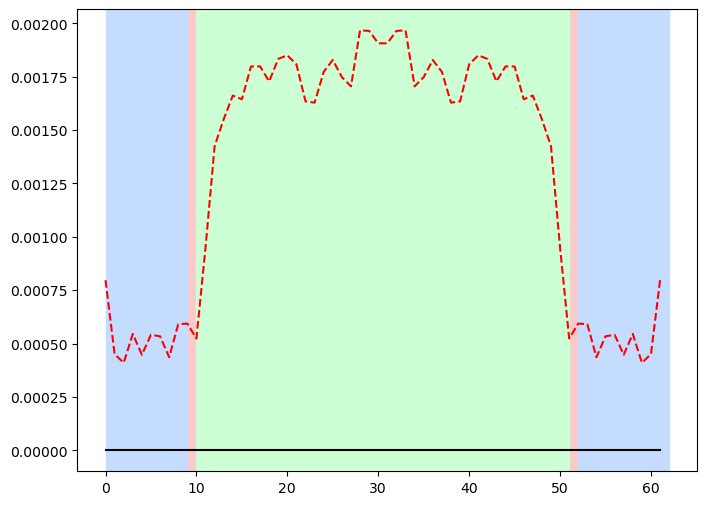

In [5]:
x = np.arange(0, widthD + widthF + widthP+ widthF + widthD)

fig, axs = plt.subplots(1, 1, figsize=(8, 6))
# axs.set_title(f"V/t = {V0}, V'/t={V_prime0}, T/t={T}, hx/t={h0}")

axs.axvspan(widthD - 1, widthD, color='#FACACA')
axs.axvspan(0, widthD - 1, color='#C4DCFF')

axs.axvspan(widthD + widthF + widthP, widthD + widthF + widthP+1, color='#FACACA')
axs.axvspan(widthD + widthF-1, widthD + widthF + widthP, color='#CCFFD3')
axs.axvspan(widthD + widthF + widthP + widthF,  widthD + widthF + widthP+ widthF + widthD, color='#C4DCFF')

# axs.plot(x, np.real(H.F0), label="onsite")
# axs.plot(x, np.real(F.dwave), label="F.dwave")
# axs.plot(x, np.real(F.swave), label="F.swave")

# axs.plot(x, np.real(F.px), label="ud:p_x-wave")
# axs.plot(x, np.imag(F.py), "--", label="ud:p_y-wave")

axs.plot(x, np.real(Fuu.px), label="uu:p_x-wave", color='black')
axs.plot(x, np.imag(Fuu.py+Fdd.py)/2, "--", label="uu:p_y-wave", color='red')
# axs.set_xlabel("x", fontsize=15)

# axs.set_yticks([0.0, 0.01, 0.02, 0.03, 0.04])
# axs.set_xticks([])
# axs.set_yticks([])

# axs.tick_params(axis='both', labelsize=12)

# axs.set_ylim(0.0, 0.04)
# axs.set_xlim(0.0, 61)

# axs.axvline(x[int(widthD+widthF+widthP/2)])
# axs.legend(fontsize=16, loc='center')
# print(np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)]/2)
# print()
# plt.savefig("../figures/DFPFD.svg", bbox_inches='tight')
plt.show()

In [6]:
print(H.free_energy(T))
print(H.free)

-26461.087943759205
-26461.087943759205


In [ ]:
print(H.free_energy(T))
print(H.free)

-26461.087943759205
-26461.087943759205
